In [2]:
df = pd.read_csv("Keerthana_Customer_Segmentation_Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()



Dataset loaded successfully!
Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,49,123,78
1,2,Female,56,65,92
2,3,Male,66,68,69
3,4,Male,69,22,47
4,5,Male,49,41,94


In [3]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Dataset Shape:
(200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,44.455000,75.585000,50.555000
std,57.879185,15.426205,35.493403,30.082082
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,32.750000,43.750000,23.750000
50%,100.500000,46.000000,73.000000,49.000000
75%,150.250000,56.000000,109.250000,76.000000
max,200.000000,70.000000,136.000000,100.000000


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nUnique Values:")
print(df.nunique())

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows:
0

Unique Values:
CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         95
Spending Score (1-100)     87
dtype: int64


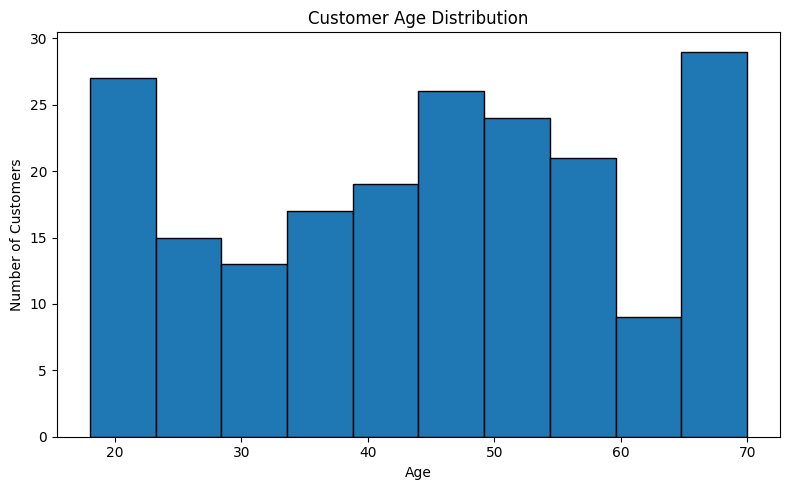

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=10, edgecolor="black")

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

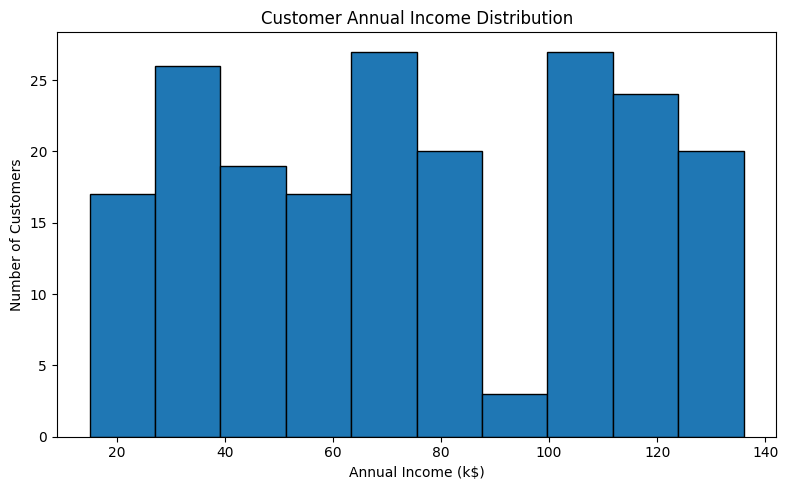

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["Annual Income (k$)"], bins=10, edgecolor="black")

plt.title("Customer Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

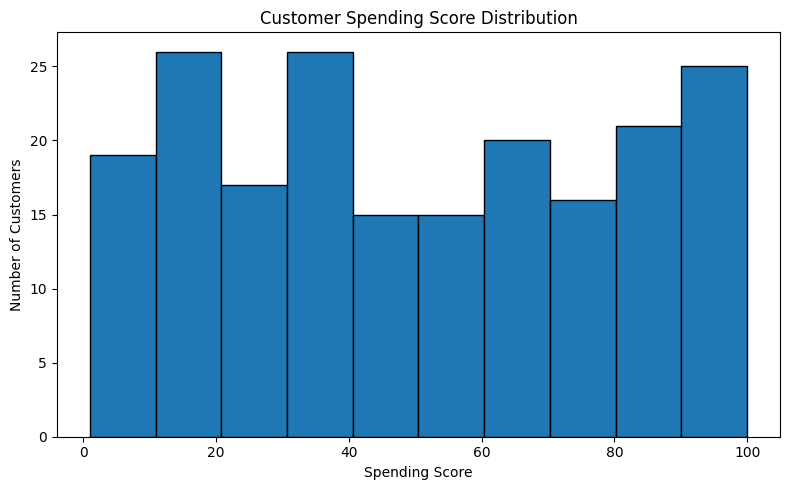

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["Spending Score (1-100)"], bins=10, edgecolor="black")

plt.title("Customer Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Customer Count by Gender:
Gender
Male      100
Female    100
Name: count, dtype: int64


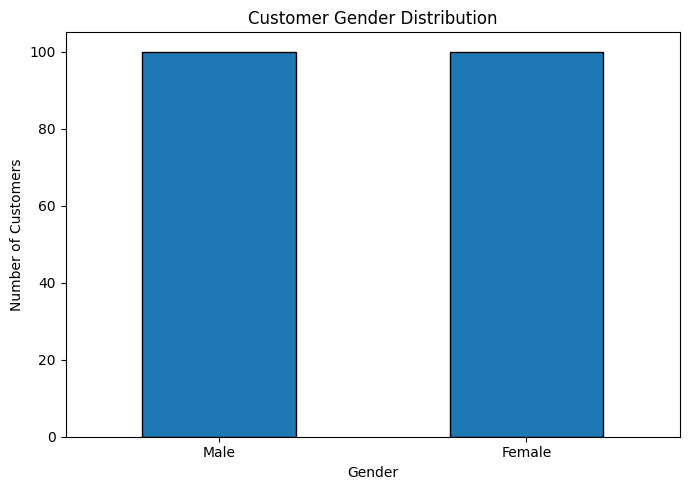

In [8]:
gender_count = df["Gender"].value_counts()

print("Customer Count by Gender:")
print(gender_count)

plt.figure(figsize=(7, 5))

gender_count.plot(kind="bar", edgecolor="black")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

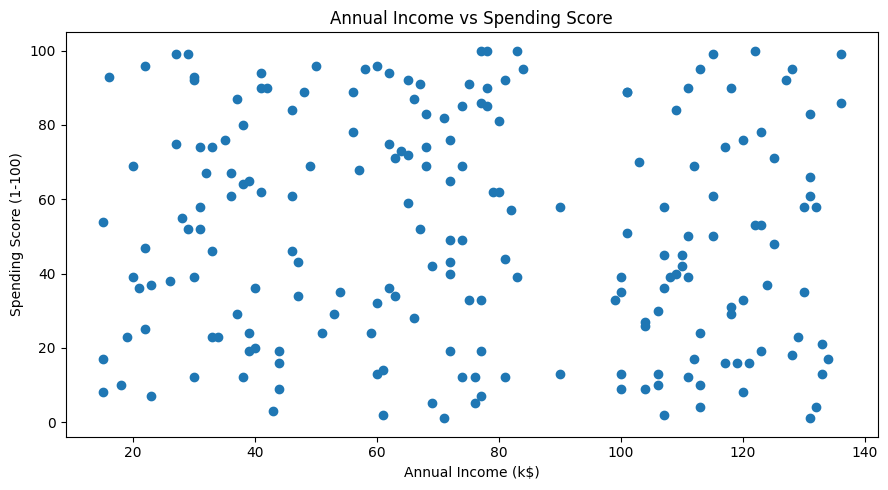

In [9]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"]
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

In [10]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data scaling completed successfully!")

Data scaling completed successfully!


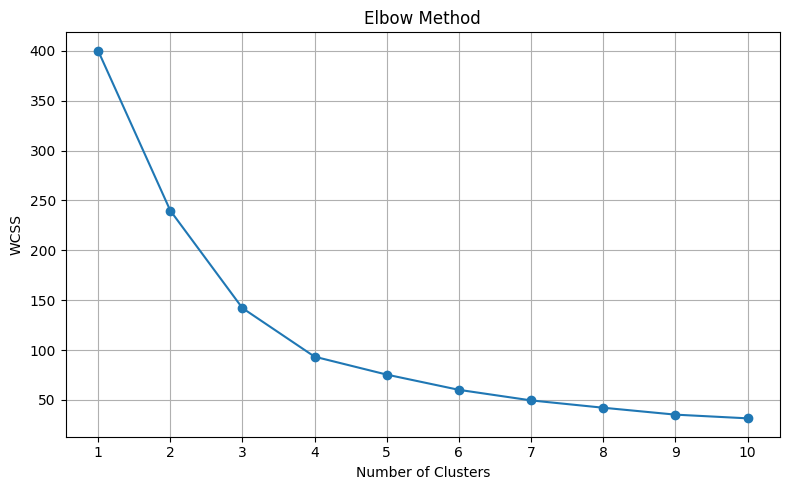

In [11]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer Segmentation Completed!")

print("\nCustomer Groups:")
print(df["Cluster"].value_counts().sort_index())

print("\nDataset with Cluster Labels:")
df.head()

Customer Segmentation Completed!

Customer Groups:
Cluster
0    27
1    53
2    40
3    48
4    32
Name: count, dtype: int64

Dataset with Cluster Labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,49,123,78,0
1,2,Female,56,65,92,2
2,3,Male,66,68,69,2
3,4,Male,69,22,47,4
4,5,Male,49,41,94,4


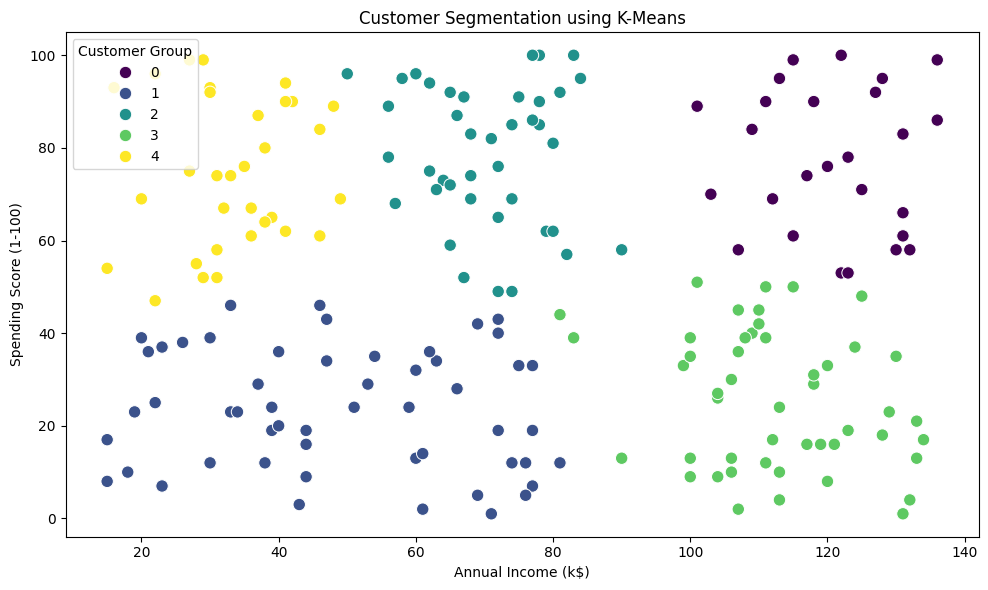

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Group")

plt.tight_layout()
plt.show()

In [14]:
cluster_analysis = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "CustomerID": "count"
})

cluster_analysis.rename(
    columns={"CustomerID": "Number of Customers"},
    inplace=True
)

print("Customer Segment Analysis:")
print(cluster_analysis.round(2))

Customer Segment Analysis:
           Age  Annual Income (k$)  Spending Score (1-100)  \
Cluster                                                      
0        46.89              119.96                   77.67   
1        44.08               49.02                   23.53   
2        42.72               70.45                   78.70   
3        44.06              112.42                   25.65   
4        45.78               33.31                   74.62   

         Number of Customers  
Cluster                       
0                         27  
1                         53  
2                         40  
3                         48  
4                         32  


In [15]:
cluster_names = {
    0: "High Income - High Spending",
    1: "Low Income - Low Spending",
    2: "Average Customers",
    3: "High Income - Low Spending",
    4: "Low Income - High Spending"
}

df["Customer Segment"] = df["Cluster"].map(cluster_names)

print("Customer Segment Names:")
print(df[["CustomerID", "Cluster", "Customer Segment"]].head(10))

Customer Segment Names:
   CustomerID  Cluster             Customer Segment
0           1        0  High Income - High Spending
1           2        2            Average Customers
2           3        2            Average Customers
3           4        4   Low Income - High Spending
4           5        4   Low Income - High Spending
5           6        4   Low Income - High Spending
6           7        0  High Income - High Spending
7           8        4   Low Income - High Spending
8           9        1    Low Income - Low Spending
9          10        0  High Income - High Spending


Number of Customers in Each Segment:
Customer Segment
Low Income - Low Spending      53
High Income - Low Spending     48
Average Customers              40
Low Income - High Spending     32
High Income - High Spending    27
Name: count, dtype: int64


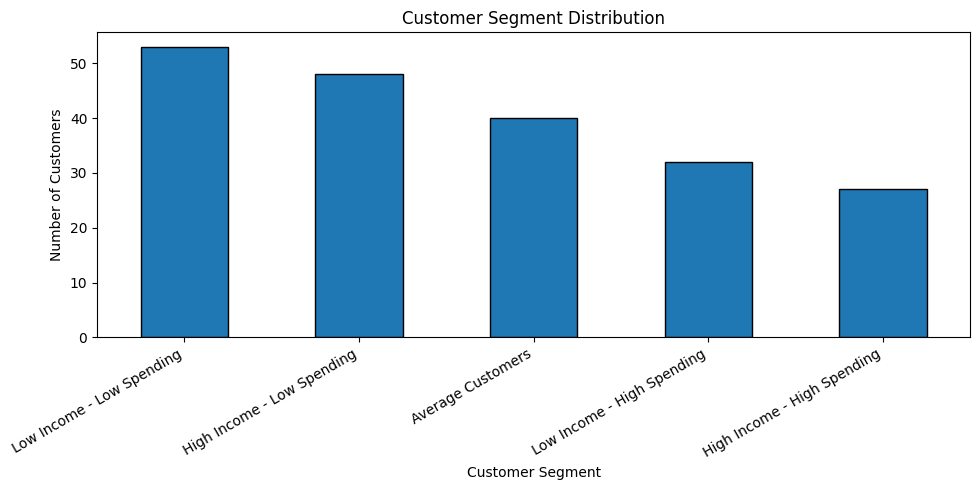

In [16]:
segment_count = df["Customer Segment"].value_counts()

print("Number of Customers in Each Segment:")
print(segment_count)

plt.figure(figsize=(10, 5))

segment_count.plot(kind="bar", edgecolor="black")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [17]:
df.to_csv("Keerthana_Customer_Segmentation_Result.csv", index=False)

print("Customer Segmentation Results Saved Successfully!")

Customer Segmentation Results Saved Successfully!


Conclusion

The Customer Segmentation project was successfully completed using Python.

In this project, customer data was analyzed based on annual income and spending score.

The K-Means Clustering algorithm was used to divide customers into five groups. Data visualization helped understand customer purchasing behaviour and spending patterns.

The project used Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

This analysis helps businesses understand different customer groups and develop suitable marketing strategies for each segment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!
